# Choosing the simulation engine

Every job runs on one of three exact engines: a statevector for ideal circuits, a density matrix for noisy ones, and
Monte-Carlo trajectories for noisy circuits too wide for a density matrix. `engine: "auto"` picks the cheaper one, and the
response says which ran and how much memory it planned for.

In [1]:
from qputwin_demo import *

connect()

QPUTwin at http://localhost:8000: ready, 7 twins reachable


{'status': 'ready',
 'instance': '02f7e5c0c4f6:7:0b2c9c',
 'job_store': 'ok',
 'backends_reachable': ['quantinuum_helios',
  'ionq_forte',
  'rigetti_ankaa_3',
  'iqm_emerald',
  'ibm_heron',
  'ibm_nighthawk',
  'google_willow']}

## 1. What `auto` chooses

For noisy jobs the density matrix is used while 2ⁿ ≤ 4 × trajectories and n ≤ 12; wider jobs switch to trajectories. The response's `telemetry.workload` records the decision.

In [2]:
rows = []
for n in (4, 8, 10, 12, 13, 16):
    for shots in (64, 1024):
        r = run("quantinuum_helios", ghz(n), shots=shots, noise=True)
        w = r["telemetry"]["workload"]
        rows.append({"qubits": n, "shots": shots, "engine": w["engine"], "state bytes": w["state_bytes"]})
pd.DataFrame(rows).pivot(index="qubits", columns="shots", values="engine")

shots,64,1024
qubits,,
4,density_matrix,density_matrix
8,density_matrix,density_matrix
10,trajectory,density_matrix
12,trajectory,density_matrix
13,trajectory,trajectory
16,trajectory,trajectory


## 2. Two exact noisy engines agree

Forcing the density matrix and the trajectory engine on the same noisy circuit gives the same distribution, up to sampling noise.

engines: density_matrix and trajectory
Hellinger fidelity between them: 0.99922


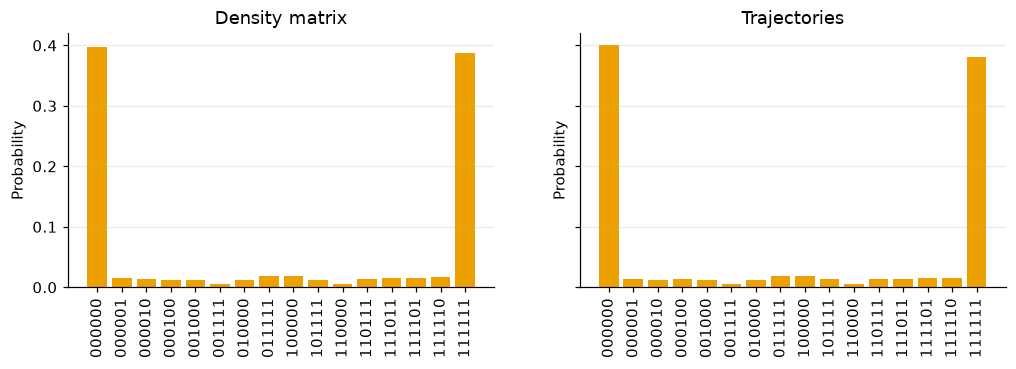

In [3]:
prog = ghz(6)
dm = run("iqm_emerald", prog, shots=50000, noise=True, engine="density_matrix")
tr = run("iqm_emerald", prog, shots=50000, noise=True, engine="trajectory")
print("engines:", dm["telemetry"]["workload"]["engine"], "and", tr["telemetry"]["workload"]["engine"])
print("Hellinger fidelity between them:", round(hellinger(dm["result"]["counts"], tr["result"]["counts"]), 5))
fig, axes = plt.subplots(1, 2, figsize=(11, 3), sharey=True)
plot_counts(dm["result"]["counts"], "Density matrix", ax=axes[0], color=COLORS["iqm_emerald"])
plot_counts(tr["result"]["counts"], "Trajectories", ax=axes[1], color=COLORS["iqm_emerald"])
plt.show()

## 3. The exact statevector

`return_statevector: true` returns the amplitudes before measurement. For a three-qubit quantum Fourier transform of |1⟩, every amplitude has magnitude 1/√8 and the phases step by π/4 (a phase of −3·π/4 is the same as 5·π/4).

In [4]:
qft3_of_one = HEADER + """qreg q[3];
creg c[3];
x q[0];
h q[2];
cu1(pi/2) q[1],q[2];
cu1(pi/4) q[0],q[2];
h q[1];
cu1(pi/2) q[0],q[1];
h q[0];
swap q[0],q[2];
measure q -> c;
"""
sv = run("quantinuum_helios", qft3_of_one, shots=1, return_statevector=True)["result"]["statevector"]
amps = np.array([complex(re, im) for re, im in sv])
pd.DataFrame({"basis": [format(i, "03b") for i in range(8)], "|amplitude|^2": np.round(abs(amps) ** 2, 6),
              "phase / (pi/4)": np.round(np.angle(amps) / (np.pi / 4), 6)})

,basis,|amplitude|^2,phase / (pi/4)
0,000,0.125,-0.0
1,001,0.125,1.0
2,010,0.125,2.0
3,011,0.125,3.0
4,100,0.125,4.0
5,101,0.125,-3.0
6,110,0.125,-2.0
7,111,0.125,-1.0


## 4. The noisy density matrix and its purity

`return_density_matrix: true` returns ρ for small noisy circuits. A noisy Bell pair is almost pure on Helios and visibly mixed on Emerald.

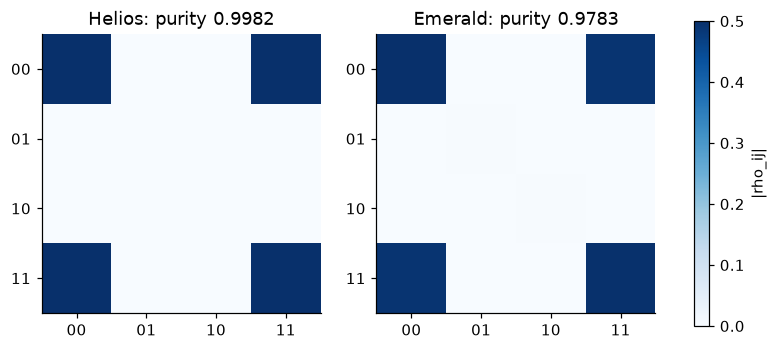

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, b in zip(axes, ["quantinuum_helios", "iqm_emerald"]):
    r = run(b, bell(), shots=1000, noise=True, return_density_matrix=True)
    rho = np.array([[complex(re, im) for re, im in row] for row in r["result"]["density_matrix"]])
    im = ax.imshow(abs(rho), cmap="Blues", vmin=0, vmax=0.5)
    ax.set_xticks(range(4), ["00", "01", "10", "11"]); ax.set_yticks(range(4), ["00", "01", "10", "11"])
    ax.set_title(f"{NAMES[b]}: purity {r['result']['noise']['purity']:.4f}")
    ax.grid(False)
fig.colorbar(im, ax=axes, label="|rho_ij|")
plt.show()

## 5. The memory guard refuses what cannot fit

Before running, each worker estimates the peak memory and compares it with what its container has. A job that cannot fit is refused at once with the numbers, instead of crashing the worker.

In [6]:
for n in (20, 24, 32):
    r = run("quantinuum_helios", ghz(n), shots=16)
    if r["http_status"] == 200:
        w = r["telemetry"]["workload"]
        print(f"{n} qubits: ran, state {w['state_bytes'] / 2**20:.0f} MiB, estimated peak {w['estimated_peak_bytes'] / 2**20:.0f} MiB")
    else:
        print(f"{n} qubits: HTTP {r['http_status']} {r['error']['type']}: {r['error']['message']}")

20 qubits: ran, state 16 MiB, estimated peak 164 MiB
24 qubits: ran, state 256 MiB, estimated peak 704 MiB
32 qubits: HTTP 422 ResourceLimitError: a dense 32-qubit complex128 statevector run needs ~96.0 GiB but only 4.3 GiB is available to this worker; at most 27 simulated qubits fit (use complex64 precision, raise the container memory limit, or touch fewer qubits)


## 6. What each engine costs

The workload report gives the state size, the planned peak and the engine time. The density matrix grows as 4ⁿ, the statevector and each trajectory as 2ⁿ.

In [7]:
rows = []
for n in (6, 8, 10):
    for engine, noise in (("statevector", None), ("density_matrix", True), ("trajectory", True)):
        r = run("quantinuum_helios", scrambler(n, 6), shots=256, noise=noise, engine=engine)
        w = r["telemetry"]["workload"]
        rows.append({"qubits": n, "engine": engine, "state bytes": w["state_bytes"],
                     "engine ms": round(r["telemetry"]["breakdown"]["simulation_ms"], 2)})
pd.DataFrame(rows).pivot(index="qubits", columns="engine", values=["state bytes", "engine ms"])

state bytes                             engine ms              \
engine density_matrix statevector trajectory density_matrix statevector   
qubits                                                                    
6             65536.0      1024.0     1024.0           4.55        1.36   
8           1048576.0      4096.0     4096.0          15.35        1.85   
10         16777216.0     16384.0    16384.0          38.57        2.31   

                   
engine trajectory  
qubits             
6           40.53  
8           57.46  
10         127.97

## Takeaways

- `auto` uses the density matrix for small noisy jobs and trajectories beyond them; the response records the choice.
- The two noisy engines agree, so the choice changes cost, not the answer.
- Jobs that cannot fit are refused before they run.